In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import seaborn as sns




In [ ]:
from google.colab import files
uploaded = files.upload()

Saving crude_type_model_data.csv to crude_type_model_data.csv


In [ ]:
df = pd.read_csv('crude_type_model_data.csv')

In [ ]:
df.head(2)

,crude,log10_viscosity_40c_cst,nitrogen_ppm,sulfur_wt_pct,nickel_plus_vanadium_ppm,tan_mgkoh_g,rvp_kpa,api_gravity_baseline_only,crude_type
0,Bakken,0.2945,453.0,0.08,0.8,0.07,74.4,44.0,Light
1,Alaskan North Slope (ANS),0.7980,1725.0,1.04,41.3,0.41,48.3,32.3,Medium


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42 entries, 0 to 41
Data columns (total 9 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   crude                      42 non-null     object 
 1   log10_viscosity_40c_cst    42 non-null     float64
 2   nitrogen_ppm               42 non-null     float64
 3   sulfur_wt_pct              42 non-null     float64
 4   nickel_plus_vanadium_ppm   42 non-null     float64
 5   tan_mgkoh_g                42 non-null     float64
 6   rvp_kpa                    42 non-null     float64
 7   api_gravity_baseline_only  42 non-null     float64
 8   crude_type                 42 non-null     object 
dtypes: float64(7), object(2)
memory usage: 3.1+ KB


In [ ]:
df.describe()

,log10_viscosity_40c_cst,nitrogen_ppm,sulfur_wt_pct,nickel_plus_vanadium_ppm,tan_mgkoh_g,rvp_kpa,api_gravity_baseline_only
count,42.000000,42.000000,42.000000,42.000000,42.000000,42.000000,42.000000
mean,0.763664,1384.821429,0.584524,24.035714,0.515476,45.447619,36.209524
std,0.579741,1028.003202,0.843660,40.777121,0.642560,17.502547,12.120670
min,-0.397900,0.500000,0.000000,0.000000,0.010000,3.500000,17.900000
25%,0.408700,491.750000,0.165000,2.000000,0.075000,39.675000,29.375000
50%,0.803800,1450.000000,0.335000,11.850000,0.330000,47.200000,33.150000
75%,1.032400,1951.000000,0.590000,28.025000,0.595000,55.475000,40.500000
max,2.240000,4323.000000,3.870000,201.000000,3.190000,86.600000,77.500000


In [ ]:
import pandas as pd
from sklearn.preprocessing import LabelEncoder

df = pd.read_csv("crude_type_model_data.csv")

# Create the new dataframe
df_new = df.copy()

# Clean and encode the column in df_new only
df_new["crude_type"] = df_new["crude_type"].astype(str).str.strip()

le = LabelEncoder()
df_new["crude_type"] = le.fit_transform(df_new["crude_type"]).astype(float)

# Mapping of crude names to numbers
mapping = dict(zip(le.classes_, le.transform(le.classes_)))
print(mapping)

print(df_new.head())   # encoded
print(df.head())       # original, still has strings

{'Heavy': np.int64(0), 'Light': np.int64(1), 'Medium': np.int64(2)}
                       crude  log10_viscosity_40c_cst  nitrogen_ppm  \
0                     Bakken                   0.2945         453.0   
1  Alaskan North Slope (ANS)                   0.7980        1725.0   
2            Cold Lake Blend                   2.2400        3062.0   
3                      Kearl                   2.0208        3408.0   
4                       Ebok                   1.9722        4323.0   

   sulfur_wt_pct  nickel_plus_vanadium_ppm  tan_mgkoh_g  rvp_kpa  \
0           0.08                       0.8         0.07     74.4   
1           1.04                      41.3         0.41     48.3   
2           3.87                     201.0         1.12     51.9   
3           3.83                     178.6         2.08     48.3   
4           0.44                      42.4         3.19     12.5   

   api_gravity_baseline_only  crude_type  
0                       44.0         1.0  
1         

In [ ]:
df_new

,crude,log10_viscosity_40c_cst,nitrogen_ppm,sulfur_wt_pct,nickel_plus_vanadium_ppm,tan_mgkoh_g,rvp_kpa,api_gravity_baseline_only,crude_type
0,Bakken,0.2945,453.0,0.08,0.8,0.07,74.4,44.0,1.0
1,Alaskan North Slope (ANS),0.7980,1725.0,1.04,41.3,0.41,48.3,32.3,2.0
2,Cold Lake Blend,2.2400,3062.0,3.87,201.0,1.12,51.9,19.5,0.0
3,Kearl,2.0208,3408.0,3.83,178.6,2.08,48.3,19.8,0.0
4,Ebok,1.9722,4323.0,0.44,42.4,3.19,12.5,17.9,0.0
5,Dalia,1.6712,2338.0,0.52,28.7,1.50,7.3,22.6,0.0
6,Hebron,1.2504,1903.0,0.71,6.1,0.58,22.1,27.0,0.0
7,Upper Zakum,0.7627,873.0,2.09,21.3,0.07,66.7,33.4,2.0
8,HOOPS Blend,0.7582,1058.0,1.45,22.7,0.50,60.6,33.5,2.0
9,Thunder Horse,0.7160,1003.0,0.76,18.1,0.07,47.6,34.5,2.0


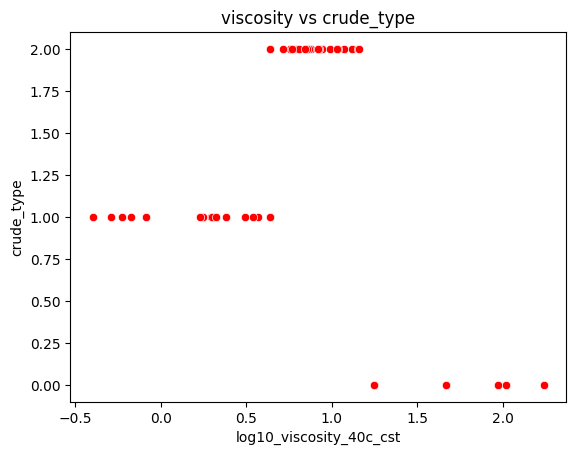

In [ ]:
sns.scatterplot(x="log10_viscosity_40c_cst", y="crude_type", data=df_new, color='red')
plt.title("viscosity vs crude_type")
plt.show()

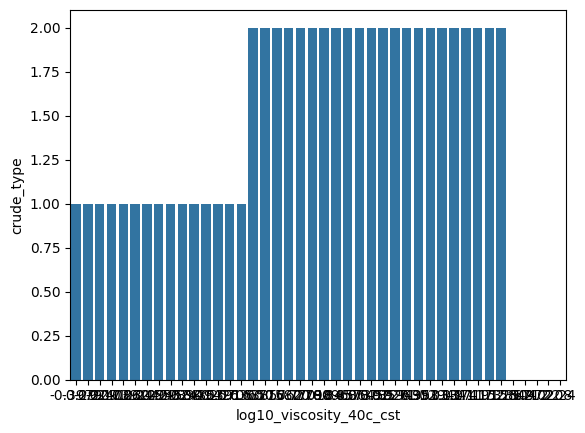

In [ ]:
sns.barplot(x="log10_viscosity_40c_cst",y="crude_type",data = df_new)
plt.show("viscosity vs crude_type")
plt.show()

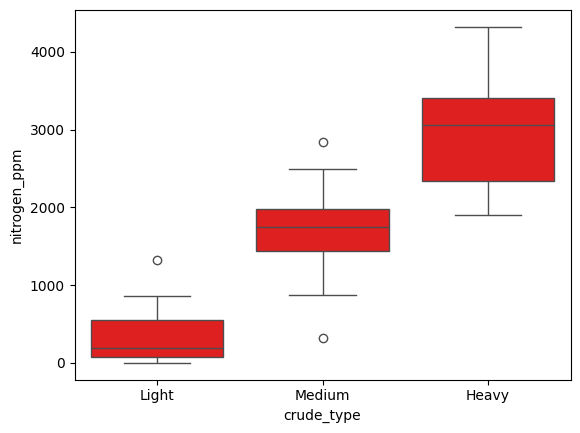

In [ ]:
sns.boxplot(y="nitrogen_ppm",x="crude_type",data = df,color='red')
plt.show("nitrogen vs crude_type")
plt.show()

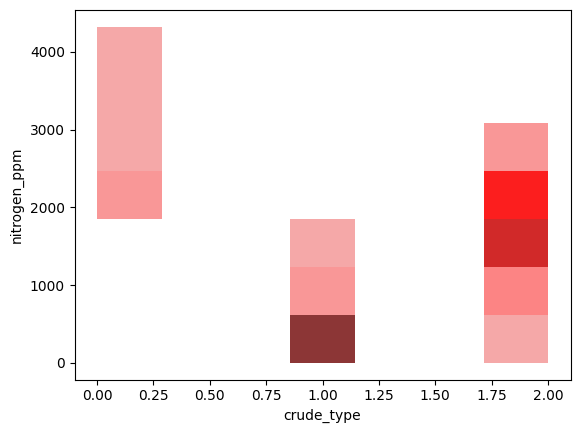

In [ ]:
sns.histplot(y="nitrogen_ppm",x="crude_type",data = df_new,color='red')
plt.show("nitrogen vs crude_type")
plt.show()

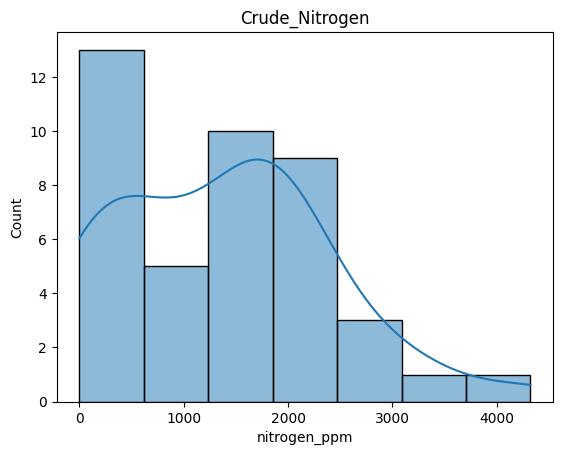

None


In [ ]:
sns.histplot(df['nitrogen_ppm'],kde=True)
plt.title("Crude_Nitrogen")
print(plt.show())

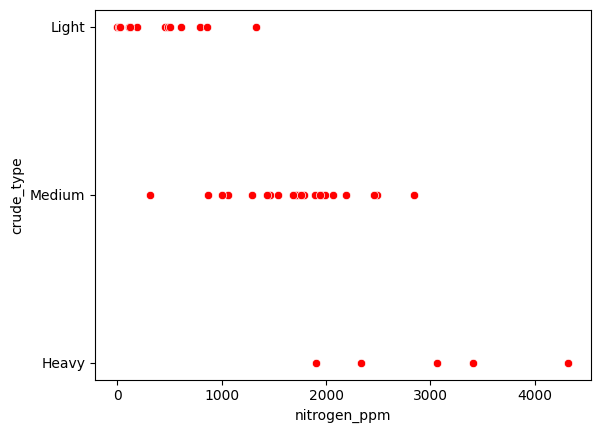

In [ ]:
sns.scatterplot(x="nitrogen_ppm",y="crude_type",data = df,color='red')
plt.show("nitrogen vs crude_type")
plt.show()

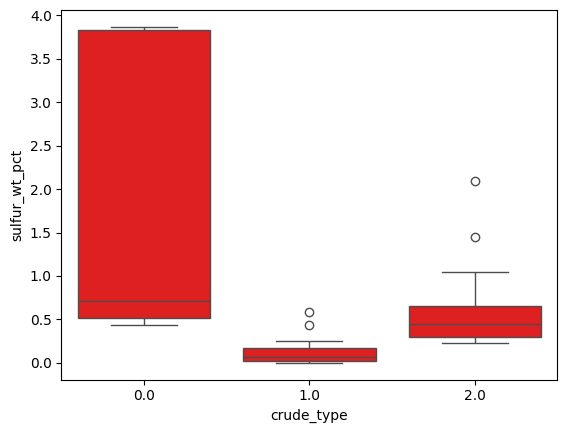

In [ ]:
sns.boxplot(y="sulfur_wt_pct",x="crude_type",data = df_new,color='red')
plt.show("sulfur vs crude_type")
plt.show()

In [ ]:
plt.scatter(x="api_gravity_baseline_only",y="sulfur_wt_pct",data = df_new,color='red')
plt.xlabel("api")
plt.ylabel("sulfur")
plt.show("sulfur vs API_Gravity")

In [ ]:
X = df_new.iloc[:,1:7]
y = df_new.iloc[:, -1]
Z = df_new['api_gravity_baseline_only']

In [ ]:
X

,log10_viscosity_40c_cst,nitrogen_ppm,sulfur_wt_pct,nickel_plus_vanadium_ppm,tan_mgkoh_g,rvp_kpa
0,0.2945,453.0,0.08,0.8,0.07,74.4
1,0.7980,1725.0,1.04,41.3,0.41,48.3
2,2.2400,3062.0,3.87,201.0,1.12,51.9
3,2.0208,3408.0,3.83,178.6,2.08,48.3
4,1.9722,4323.0,0.44,42.4,3.19,12.5
5,1.6712,2338.0,0.52,28.7,1.50,7.3
6,1.2504,1903.0,0.71,6.1,0.58,22.1
7,0.7627,873.0,2.09,21.3,0.07,66.7
8,0.7582,1058.0,1.45,22.7,0.50,60.6
9,0.7160,1003.0,0.76,18.1,0.07,47.6


In [ ]:
y

,crude_type
0,1.0
1,2.0
2,0.0
3,0.0
4,0.0
5,0.0
6,0.0
7,2.0
8,2.0
9,2.0


In [ ]:
Z

,api_gravity_baseline_only
0,44.0
1,32.3
2,19.5
3,19.8
4,17.9
5,22.6
6,27.0
7,33.4
8,33.5
9,34.5


In [ ]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.20, random_state = 0)
from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import LeaveOneOut, cross_val_predict
from sklearn.metrics import confusion_matrix


In [ ]:
X_train
y_train

,crude_type
31,1.0
29,2.0
20,1.0
39,2.0
2,0.0
41,2.0
18,2.0
15,1.0
22,1.0
16,2.0


In [ ]:
lr = LinearRegression()
lr.fit(X_train,y_train)
y_pred = lr.predict(X_test)
r2_score = lr.score(X_test,y_test)
print(r2_score)



0.24496987553661131


In [ ]:
coef_
interept_

NameError: name 'coef_' is not defined

In [ ]:
y_pred


array([1.70013203, 1.53770936, 1.22233208, 1.37220122, 1.30551914,
       1.57583084, 1.80765613, 1.37046188, 1.33976829])

In [ ]:
y_test

,crude_type
30,2.0
36,2.0
27,1.0
4,0.0
10,2.0
25,2.0
28,2.0
11,1.0
37,1.0


In [ ]:
log = LogisticRegression(C=10,max_iter=5000)
log.fit(X_train,y_train)
y_pred = log.predict(X_test)
r2_score = log.score(X_test,y_test)
print(r2_score)

0.8888888888888888


In [ ]:
from sklearn.model_selection import cross_val_score
cv_scores = cross_val_score(log, X_train, y_train, cv=2, scoring='accuracy')

print("Cross-validation scores:", cv_scores)
print("Mean CV Accuracy:", cv_scores.mean())

Cross-validation scores: [0.52941176 0.8125    ]
Mean CV Accuracy: 0.6709558823529411


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


# ADDED: all models, one by one (no loops)

Everything below was added after your own cells. Your original cells above are unchanged.

* **Part A** - crude type (Light / Medium / Heavy), using your `df` (`crude_type_model_data.csv`)
* **Part B** - product yield (vol%), needs a second file: `crude_assay_dataset.csv`
* **Part C** - final models trained on all crudes + predictions for a new crude

My variables have their own names (`Xc_train`, `yc_train`, `Xr_train`, ...), so they never overwrite your `X_train`, `y_train`, `lr` or `log`. Run the cells from top to bottom.

In [ ]:
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, cross_val_score, KFold, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix
from sklearn.compose import TransformedTargetRegressor

from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.svm import SVC, SVR
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier, GradientBoostingClassifier, AdaBoostClassifier,
                              RandomForestRegressor, ExtraTreesRegressor, GradientBoostingRegressor, AdaBoostRegressor)
from sklearn.neural_network import MLPClassifier, MLPRegressor
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, ConstantKernel, WhiteKernel

## Second data file (needed for Part B and Part C)

Part B and C predict product yields, and the yields are only in `crude_assay_dataset.csv`. Run the next cell and choose that file.
(In Colab you can also drag the file into the Files panel on the left, then skip the upload cell.)

In [ ]:
from google.colab import files
uploaded_assay = files.upload()

Saving crude_assay_dataset.csv to crude_assay_dataset.csv


In [ ]:
df_assay = pd.read_csv("crude_assay_dataset.csv")

# the same two engineered inputs that are already in your crude_type_model_data.csv
df_assay["log10_viscosity_40c_cst"] = np.log10(df_assay["viscosity_40c_cst"])
df_assay["nickel_plus_vanadium_ppm"] = df_assay["nickel_ppm"] + df_assay["vanadium_ppm"]

print(df_assay.shape)

(15, 35)


# Part A - Crude type (classification)

Inputs: the 6 properties **without** API gravity (API defines the label, so it would give the answer away).
Output: `crude_type` as text (Heavy / Light / Medium). I use your original `df`, where the labels are still text.

In [ ]:
df_assay.head(2)


,crude,exxon_reference,origin,country,region,crude_type,sulfur_flavor,api_gravity,density_15c_g_cc,sulfur_wt_pct,...,vac_residue_550plus_wt,c4_minus_vol,naphtha_c5_150_vol,kerosene_150_250_vol,diesel_250_370_vol,atm_residue_370plus_vol,vgo_370_550_vol,vac_residue_550plus_vol,log10_viscosity_40c_cst,nickel_plus_vanadium_ppm
0,Bakken,BAKKEN24,North Dakota,United States,North America,Light,Sweet,44.0,0.8059,0.08,...,5.7,4.2,31.5,21.2,20.1,22.9,18.2,4.7,0.294466,0.8
1,Alaskan North Slope (ANS),ANS25Y,Alaska,United States,North America,Medium,Sour,32.3,0.8635,1.04,...,18.2,4.0,21.7,16.1,19.8,38.4,23.3,15.2,0.797960,41.3


In [ ]:
FEATURES_A = ["log10_viscosity_40c_cst", "nitrogen_ppm", "sulfur_wt_pct",
              "nickel_plus_vanadium_ppm", "tan_mgkoh_g", "rvp_kpa"]

Xc = df[FEATURES_A]
yc = df["crude_type"]

# stratify=yc keeps the Light/Medium/Heavy proportions the same in train and test
Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size=0.25, stratify=yc, random_state=42)

# Scaling for models that need it. The scaler learns from TRAIN only, then is applied to test.
scaler_c = StandardScaler()
Xc_train_s = scaler_c.fit_transform(Xc_train)
Xc_test_s = scaler_c.transform(Xc_test)

print(len(Xc_train), "train crudes /", len(Xc_test), "test crudes")
print("test set classes:", yc_test.value_counts().to_dict())

results_a = {}      # model name -> accuracy

31 train crudes / 11 test crudes
test set classes: {'Medium': 6, 'Light': 4, 'Heavy': 1}


**Which data goes to which model?** Linear / distance / neural models use the scaled data (`Xc_train_s`, `Xc_test_s`). Tree-based models and naive Bayes use the original data (`Xc_train`, `Xc_test`).

In [ ]:
Xc_train
Xc_test
yc_train
yc_test

,crude_type
22,Light
15,Light
14,Medium
5,Heavy
41,Medium
35,Light
1,Medium
25,Medium
39,Medium
7,Medium


In [ ]:
# A1. Majority-class guess (baseline)
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(Xc_train, yc_train)
y_pred = dummy.predict(Xc_test)
acc = dummy.score(Xc_test, yc_test)
print("Majority-class guess (baseline)  accuracy:", round(acc, 3))
results_a["Majority-class guess (baseline)"] = acc

Majority-class guess (baseline)  accuracy: 0.545


In [ ]:
# A2. Logistic Regression
logreg = LogisticRegression(C=10, max_iter=5000)
logreg.fit(Xc_train_s, yc_train)
y_pred = logreg.predict(Xc_test_s)
acc = logreg.score(Xc_test_s, yc_test)
print("Logistic Regression  accuracy:", round(acc, 3))
results_a["Logistic Regression"] = acc

Logistic Regression  accuracy: 1.0


In [ ]:
# A3. Linear Discriminant Analysis
lda = LinearDiscriminantAnalysis()
lda.fit(Xc_train_s, yc_train)
y_pred = lda.predict(Xc_test_s)
acc = lda.score(Xc_test_s, yc_test)
print("Linear Discriminant Analysis  accuracy:", round(acc, 3))
results_a["Linear Discriminant Analysis"] = acc

In [ ]:
# A4. Gaussian Naive Bayes
nb = GaussianNB()
nb.fit(Xc_train, yc_train)
y_pred = nb.predict(Xc_test)
acc = nb.score(Xc_test, yc_test)
print("Gaussian Naive Bayes  accuracy:", round(acc, 3))
results_a["Gaussian Naive Bayes"] = acc

In [ ]:
# A5. KNN (k=3)
knn3 = KNeighborsClassifier(n_neighbors=3)
knn3.fit(Xc_train_s, yc_train)
y_pred = knn3.predict(Xc_test_s)
acc = knn3.score(Xc_test_s, yc_test)
print("KNN (k=3)  accuracy:", round(acc, 3))
results_a["KNN (k=3)"] = acc

In [ ]:
# A6. KNN (k=5)
knn5 = KNeighborsClassifier(n_neighbors=5)
knn5.fit(Xc_train_s, yc_train)
y_pred = knn5.predict(Xc_test_s)
acc = knn5.score(Xc_test_s, yc_test)
print("KNN (k=5)  accuracy:", round(acc, 3))
results_a["KNN (k=5)"] = acc

In [ ]:
# A7. SVM (linear)
svm_lin = SVC(kernel="linear", C=1)
svm_lin.fit(Xc_train_s, yc_train)
y_pred = svm_lin.predict(Xc_test_s)
acc = svm_lin.score(Xc_test_s, yc_test)
print("SVM (linear)  accuracy:", round(acc, 3))
results_a["SVM (linear)"] = acc

In [ ]:
# A8. SVM (RBF)
svm_rbf = SVC(kernel="rbf", C=10)
svm_rbf.fit(Xc_train_s, yc_train)
y_pred = svm_rbf.predict(Xc_test_s)
acc = svm_rbf.score(Xc_test_s, yc_test)
print("SVM (RBF)  accuracy:", round(acc, 3))
results_a["SVM (RBF)"] = acc

In [ ]:
# A9. Decision Tree (depth 2)
dt2 = DecisionTreeClassifier(max_depth=2, random_state=42)
dt2.fit(Xc_train, yc_train)
y_pred = dt2.predict(Xc_test)
acc = dt2.score(Xc_test, yc_test)
print("Decision Tree (depth 2)  accuracy:", round(acc, 3))
results_a["Decision Tree (depth 2)"] = acc

In [ ]:
# A10. Decision Tree (depth 3)
dt3 = DecisionTreeClassifier(max_depth=3, random_state=42)
dt3.fit(Xc_train, yc_train)
y_pred = dt3.predict(Xc_test)
acc = dt3.score(Xc_test, yc_test)
print("Decision Tree (depth 3)  accuracy:", round(acc, 3))
results_a["Decision Tree (depth 3)"] = acc

In [ ]:
# A11. Decision Tree (no depth limit)
dt_full = DecisionTreeClassifier(random_state=42)
dt_full.fit(Xc_train, yc_train)
y_pred = dt_full.predict(Xc_test)
acc = dt_full.score(Xc_test, yc_test)
print("Decision Tree (no depth limit)  accuracy:", round(acc, 3))
results_a["Decision Tree (no depth limit)"] = acc

In [ ]:
# A12. Random Forest
rf = RandomForestClassifier(n_estimators=200, random_state=42)
rf.fit(Xc_train, yc_train)
y_pred = rf.predict(Xc_test)
acc = rf.score(Xc_test, yc_test)
print("Random Forest  accuracy:", round(acc, 3))
results_a["Random Forest"] = acc

In [ ]:
# A13. Extra Trees
et = ExtraTreesClassifier(n_estimators=200, random_state=42)
et.fit(Xc_train, yc_train)
y_pred = et.predict(Xc_test)
acc = et.score(Xc_test, yc_test)
print("Extra Trees  accuracy:", round(acc, 3))
results_a["Extra Trees"] = acc

In [ ]:
# A14. Gradient Boosting
gb = GradientBoostingClassifier(random_state=42)
gb.fit(Xc_train, yc_train)
y_pred = gb.predict(Xc_test)
acc = gb.score(Xc_test, yc_test)
print("Gradient Boosting  accuracy:", round(acc, 3))
results_a["Gradient Boosting"] = acc

In [ ]:
# A15. AdaBoost
ada = AdaBoostClassifier(random_state=42)
ada.fit(Xc_train, yc_train)
y_pred = ada.predict(Xc_test)
acc = ada.score(Xc_test, yc_test)
print("AdaBoost  accuracy:", round(acc, 3))
results_a["AdaBoost"] = acc

In [ ]:
# A16. Neural Network (MLP)
mlp = MLPClassifier(hidden_layer_sizes=(16,), max_iter=2000, random_state=42)
mlp.fit(Xc_train_s, yc_train)
y_pred = mlp.predict(Xc_test_s)
acc = mlp.score(Xc_test_s, yc_test)
print("Neural Network (MLP)  accuracy:", round(acc, 3))
results_a["Neural Network (MLP)"] = acc

## Part A - compare all models

In [ ]:
table_a = pd.Series(results_a).sort_values(ascending=False).round(3).to_frame("accuracy")
print(table_a)

In [ ]:
table_a["accuracy"].sort_values().plot(kind="barh", figsize=(7, 6))
plt.xlabel("Accuracy on the test set")
plt.title("Crude type - accuracy of each model")
plt.tight_layout()
plt.show()

In [ ]:
# Which crudes does a model get wrong? Example: Decision Tree (depth 3)
y_pred = dt3.predict(Xc_test)
print("rows = true, columns = predicted  (Heavy, Medium, Light)")
print(confusion_matrix(yc_test, y_pred, labels=["Heavy", "Medium", "Light"]))
print("wrong:", list(df.loc[Xc_test.index[y_pred != yc_test], "crude"]))

**Important:** the test set has only ~11 crudes, so each crude is worth about 9 percentage points and the ranking changes if you change `random_state`. Use the cross-validation cell below for a fairer check.

In [ ]:
# Fairer check: 5-fold cross-validation of ONE model (every crude is used for testing once)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(DecisionTreeClassifier(max_depth=3, random_state=42), Xc, yc, cv=cv, scoring="accuracy")
print("fold accuracies:", scores.round(2), " mean:", scores.mean().round(3))

# Part B - Product yield (regression)

Inputs: API gravity + 7 other properties. Output: one yield in vol%. Change `TARGET` to predict a different yield.
R2 = share of the variation explained (1.0 = perfect; **below 0 = worse than just guessing the average**).

In [ ]:
TARGET = "atm_residue_370plus_vol"     # also try: "naphtha_c5_150_vol", "kerosene_150_250_vol", "diesel_250_370_vol"

FEATURES_B = ["api_gravity", "sulfur_wt_pct", "log10_viscosity_40c_cst", "nickel_plus_vanadium_ppm",
              "nitrogen_ppm", "tan_mgkoh_g", "rvp_kpa", "pour_point_c"]

Xr = df_assay[FEATURES_B]
yr = df_assay[TARGET]

Xr_train, Xr_test, yr_train, yr_test = train_test_split(Xr, yr, test_size=0.25, random_state=42)

scaler_r = StandardScaler()
Xr_train_s = scaler_r.fit_transform(Xr_train)
Xr_test_s = scaler_r.transform(Xr_test)

print(len(Xr_train), "train crudes /", len(Xr_test), "test crudes   | target:", TARGET)

results_b = {}      # model name -> R2

Linear / distance / neural models use the scaled data (`Xr_train_s`, `Xr_test_s`); tree models use the original data.

In [ ]:
# B1. Mean guess (baseline)
mean_model = DummyRegressor()
mean_model.fit(Xr_train, yr_train)
y_pred = mean_model.predict(Xr_test)
r2 = mean_model.score(Xr_test, yr_test)
print("Mean guess (baseline)  R2:", round(r2, 3))
results_b["Mean guess (baseline)"] = r2

In [ ]:
# B2. Linear Regression
lin_reg = LinearRegression()
lin_reg.fit(Xr_train_s, yr_train)
y_pred = lin_reg.predict(Xr_test_s)
r2 = lin_reg.score(Xr_test_s, yr_test)
print("Linear Regression  R2:", round(r2, 3))
results_b["Linear Regression"] = r2

In [ ]:
# B3. Ridge
ridge = Ridge(alpha=1.0)
ridge.fit(Xr_train_s, yr_train)
y_pred = ridge.predict(Xr_test_s)
r2 = ridge.score(Xr_test_s, yr_test)
print("Ridge  R2:", round(r2, 3))
results_b["Ridge"] = r2

In [ ]:
# B4. Lasso
lasso = Lasso(alpha=0.1)
lasso.fit(Xr_train_s, yr_train)
y_pred = lasso.predict(Xr_test_s)
r2 = lasso.score(Xr_test_s, yr_test)
print("Lasso  R2:", round(r2, 3))
results_b["Lasso"] = r2

In [ ]:
# B5. Elastic Net
enet = ElasticNet(alpha=0.1, l1_ratio=0.5)
enet.fit(Xr_train_s, yr_train)
y_pred = enet.predict(Xr_test_s)
r2 = enet.score(Xr_test_s, yr_test)
print("Elastic Net  R2:", round(r2, 3))
results_b["Elastic Net"] = r2

In [ ]:
# B6. KNN (k=3)
knn_r = KNeighborsRegressor(n_neighbors=3)
knn_r.fit(Xr_train_s, yr_train)
y_pred = knn_r.predict(Xr_test_s)
r2 = knn_r.score(Xr_test_s, yr_test)
print("KNN (k=3)  R2:", round(r2, 3))
results_b["KNN (k=3)"] = r2

In [ ]:
# B7. SVR (RBF)
svr = TransformedTargetRegressor(regressor=SVR(C=10), transformer=StandardScaler())
svr.fit(Xr_train_s, yr_train)
y_pred = svr.predict(Xr_test_s)
r2 = svr.score(Xr_test_s, yr_test)
print("SVR (RBF)  R2:", round(r2, 3))
results_b["SVR (RBF)"] = r2

In [ ]:
# B8. Decision Tree (depth 3)
tree_r = DecisionTreeRegressor(max_depth=3, random_state=42)
tree_r.fit(Xr_train, yr_train)
y_pred = tree_r.predict(Xr_test)
r2 = tree_r.score(Xr_test, yr_test)
print("Decision Tree (depth 3)  R2:", round(r2, 3))
results_b["Decision Tree (depth 3)"] = r2

In [ ]:
# B9. Random Forest
rf_r = RandomForestRegressor(n_estimators=200, random_state=42)
rf_r.fit(Xr_train, yr_train)
y_pred = rf_r.predict(Xr_test)
r2 = rf_r.score(Xr_test, yr_test)
print("Random Forest  R2:", round(r2, 3))
results_b["Random Forest"] = r2

In [ ]:
# B10. Extra Trees
et_r = ExtraTreesRegressor(n_estimators=200, random_state=42)
et_r.fit(Xr_train, yr_train)
y_pred = et_r.predict(Xr_test)
r2 = et_r.score(Xr_test, yr_test)
print("Extra Trees  R2:", round(r2, 3))
results_b["Extra Trees"] = r2

In [ ]:
# B11. Gradient Boosting
gb_r = GradientBoostingRegressor(random_state=42)
gb_r.fit(Xr_train, yr_train)
y_pred = gb_r.predict(Xr_test)
r2 = gb_r.score(Xr_test, yr_test)
print("Gradient Boosting  R2:", round(r2, 3))
results_b["Gradient Boosting"] = r2

In [ ]:
# B12. AdaBoost
ada_r = AdaBoostRegressor(random_state=42)
ada_r.fit(Xr_train, yr_train)
y_pred = ada_r.predict(Xr_test)
r2 = ada_r.score(Xr_test, yr_test)
print("AdaBoost  R2:", round(r2, 3))
results_b["AdaBoost"] = r2

In [ ]:
# B13. Neural Network (MLP)
mlp_r = TransformedTargetRegressor(regressor=MLPRegressor(hidden_layer_sizes=(16,), max_iter=2000, random_state=42), transformer=StandardScaler())
mlp_r.fit(Xr_train_s, yr_train)
y_pred = mlp_r.predict(Xr_test_s)
r2 = mlp_r.score(Xr_test_s, yr_test)
print("Neural Network (MLP)  R2:", round(r2, 3))
results_b["Neural Network (MLP)"] = r2

In [ ]:
# B14. Gaussian Process
gp = GaussianProcessRegressor(kernel=ConstantKernel(1.0) * RBF(1.0) + WhiteKernel(0.1), normalize_y=True, random_state=42)
gp.fit(Xr_train_s, yr_train)
y_pred = gp.predict(Xr_test_s)
r2 = gp.score(Xr_test_s, yr_test)
print("Gaussian Process  R2:", round(r2, 3))
results_b["Gaussian Process"] = r2

## Part B - compare all models

In [ ]:
table_b = pd.Series(results_b).sort_values(ascending=False).round(3).to_frame("R2")
print(table_b)

In [ ]:
table_b["R2"].sort_values().plot(kind="barh", figsize=(7, 6))
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("R2 on the test set")
plt.title("Yield: " + TARGET)
plt.tight_layout()
plt.show()

In [ ]:
# Actual vs predicted for one model (points on the diagonal = perfect prediction)
y_pred = et_r.predict(Xr_test)
plt.scatter(yr_test, y_pred)
lims = [min(yr_test.min(), y_pred.min()), max(yr_test.max(), y_pred.max())]
plt.plot(lims, lims, "k--")
plt.xlabel("Actual (vol%)"); plt.ylabel("Predicted (vol%)"); plt.title("Extra Trees - " + TARGET)
plt.show()

Same warning as Part A: ~11 test crudes is a very small test set, so treat the ranking as a first look. Check your favourite model with cross-validation:

In [ ]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)
scores = cross_val_score(ExtraTreesRegressor(n_estimators=200, random_state=42), Xr, yr, cv=cv, scoring="r2")
print("fold R2:", scores.round(2), " mean:", scores.mean().round(3))

# Part C - Your final models (trained on all 42 crudes)

Parts A and B only *compare* models on a test set. Here you train the chosen models on **all** the data and use them on a new crude.
There is no test score for these models, because every crude was used for training. Expect roughly the cross-validated performance: about 92-94% accuracy for the crude type and R2 of about 0.6-0.95 for the yields (diesel and kerosene are the hardest).

* Crude type: a Decision Tree (depth 3) and a Logistic Regression on the 6 inputs
* Yields: one Extra Trees model per yield, on API + 7 properties

In [ ]:
# C1. Final crude-type model 1: Decision Tree (depth 3), trained on ALL crudes
final_tree = DecisionTreeClassifier(max_depth=3, random_state=42)
final_tree.fit(df[FEATURES_A], df["crude_type"])
print("trained:", final_tree)

In [ ]:
# C2. Final crude-type model 2: Logistic Regression (gives smooth probabilities)
final_scaler_a = StandardScaler()
X_all_a_s = final_scaler_a.fit_transform(df[FEATURES_A])

final_logreg = LogisticRegression(C=10, max_iter=5000)
final_logreg.fit(X_all_a_s, df["crude_type"])
print("trained:", final_logreg)

In [ ]:
# C3. Final yield model: Residue (370 C+) - Extra Trees
final_residue = ExtraTreesRegressor(n_estimators=300, random_state=42)
final_residue.fit(df_assay[FEATURES_B], df_assay["atm_residue_370plus_vol"])
print("trained: residue model")

In [ ]:
# C4. Final yield model: Naphtha (C5-150 C) - Extra Trees
final_naphtha = ExtraTreesRegressor(n_estimators=300, random_state=42)
final_naphtha.fit(df_assay[FEATURES_B], df_assay["naphtha_c5_150_vol"])
print("trained: naphtha model")

In [ ]:
# C5. Final yield model: Kerosene (150-250 C) - Extra Trees
final_kerosene = ExtraTreesRegressor(n_estimators=300, random_state=42)
final_kerosene.fit(df_assay[FEATURES_B], df_assay["kerosene_150_250_vol"])
print("trained: kerosene model")

In [ ]:
# C6. Final yield model: Diesel (250-370 C) - Extra Trees
final_diesel = ExtraTreesRegressor(n_estimators=300, random_state=42)
final_diesel.fit(df_assay[FEATURES_B], df_assay["diesel_250_370_vol"])
print("trained: diesel model")

In [ ]:
# C7. A NEW crude - type in its raw lab values (example numbers, replace them with your own)
new_crude = {
    "api_gravity": 31.0,
    "sulfur_wt_pct": 0.9,
    "viscosity_40c_cst": 9.5,
    "nickel_ppm": 12.0,
    "vanadium_ppm": 15.0,
    "nitrogen_ppm": 1500,
    "tan_mgkoh_g": 0.4,
    "rvp_kpa": 45.0,
    "pour_point_c": -15,
}
new = pd.DataFrame([new_crude])
new["log10_viscosity_40c_cst"] = np.log10(new["viscosity_40c_cst"])
new["nickel_plus_vanadium_ppm"] = new["nickel_ppm"] + new["vanadium_ppm"]
print(new.T)

In [ ]:
# C8. Predict the crude type (API gravity is NOT used here - only the 6 inputs)
type_tree = final_tree.predict(new[FEATURES_A])[0]

new_a_s = final_scaler_a.transform(new[FEATURES_A])
type_logreg = final_logreg.predict(new_a_s)[0]
probs = final_logreg.predict_proba(new_a_s)[0]

print("Crude type (decision tree)       :", type_tree)
print("Crude type (logistic regression) :", type_logreg)
print("Logistic regression probabilities:")
print(pd.Series(probs, index=final_logreg.classes_).round(3))

In [ ]:
# C9. Predict the product yields
naphtha = final_naphtha.predict(new[FEATURES_B])[0]
kerosene = final_kerosene.predict(new[FEATURES_B])[0]
diesel = final_diesel.predict(new[FEATURES_B])[0]
residue = final_residue.predict(new[FEATURES_B])[0]

print(f"Naphtha  (C5-150 C) : {naphtha:5.1f} vol%")
print(f"Kerosene (150-250 C): {kerosene:5.1f} vol%")
print(f"Diesel   (250-370 C): {diesel:5.1f} vol%")
print(f"Residue  (370 C+)   : {residue:5.1f} vol%")
print(f"Sum of the four     : {naphtha + kerosene + diesel + residue:5.1f} vol%  (light gases are the rest, usually 1-5%)")

In [ ]:
# C10. Save the trained models so you can reuse them without retraining
# (in Colab the files appear in the Files panel on the left - download them before the session ends)
import joblib
joblib.dump(final_tree, "model_crude_type_tree.joblib")
joblib.dump(final_logreg, "model_crude_type_logreg.joblib")
joblib.dump(final_scaler_a, "scaler_crude_type.joblib")
joblib.dump(final_residue, "model_yield_residue.joblib")
joblib.dump(final_naphtha, "model_yield_naphtha.joblib")
joblib.dump(final_kerosene, "model_yield_kerosene.joblib")
joblib.dump(final_diesel, "model_yield_diesel.joblib")
print("saved 7 files. To reuse later:  model = joblib.load('model_yield_residue.joblib')")